# Agente inversor: baselines

El agente se compara con dos estrategias simples que no aprenden nada:

- **Agente aleatorio:** cada día elige 0 %, 50 % o 100 % al azar, con la misma
  probabilidad. Es la referencia mínima: un agente que no supere al azar no
  aprendió nada útil.
- **Comprar y mantener:** invierte el 100 % al primer cierre y no vuelve a
  operar. Es la referencia exigente: si el agente no la supera, operar no
  aportó valor frente a no hacer nada.

Como referencias adicionales se muestran **siempre en efectivo** y
**siempre 50 %**.

Aquí se evalúa en train y validación. **El período de test se reserva para la
evaluación final**, donde se aplicarán exactamente estas mismas funciones.

In [1]:
import os
from pathlib import Path

# Ejecutar desde la raíz del repositorio, como la CLI.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter
from stable_baselines3 import DQN

from rl_games_sb import backtest, investor

PERIODS = ["train", "valid"]
RANDOM_RUNS = 200  # semillas 0..199 del agente aleatorio
SEEDS = [0, 1, 2]

LABELS = {
    "total_return": "retorno total",
    "annual_return": "retorno anual",
    "volatility": "volatilidad anual",
    "sharpe": "Sharpe",
    "max_drawdown": "drawdown máximo",
    "trades": "operaciones",
    "costs": "costos ($)",
    "exposure": "exposición media",
}
PCT = ["retorno total", "retorno anual", "volatilidad anual", "drawdown máximo"]


def fmt(table):
    table = table.rename(columns=LABELS)
    return table.style.format(
        {c: "{:+.1%}" for c in PCT if c in table}
        | {"Sharpe": "{:.2f}", "operaciones": "{:.0f}", "costos ($)": "{:,.0f}", "exposición media": "{:.2f}"},
        na_rep="—",
    )

## Mismas condiciones para todos

Todas las estrategias, incluido el agente DQN, se ejecutan con
`backtest.run` sobre el mismo entorno:

In [2]:
conditions = {}
for p in PERIODS:
    env = investor.InvestorEnv(period=p)
    conditions[p] = {
        "primera decisión": env.dates[0].date(),
        "último cierre": env.dates[-1].date(),
        "decisiones": len(env.dates) - 1,
        "capital inicial": f"${investor.INITIAL_CAPITAL:,.0f}",
        "posición inicial": "efectivo",
        "costo por operación": f"{investor.COST_BPS:.0f} bps del monto negociado",
        "ejecución": "al cierre del día de la decisión",
    }
pd.DataFrame(conditions)

,train,valid
primera decisión,2009-08-03,2015-01-02
último cierre,2014-12-31,2015-12-31
decisiones,1363,251
capital inicial,"$100,000","$100,000"
posición inicial,efectivo,efectivo
costo por operación,10 bps del monto negociado,10 bps del monto negociado
ejecución,al cierre del día de la decisión,al cierre del día de la decisión


El agente DQN v1 se entrena con una penalización extra por operar, pero esa
penalización solo existe en su recompensa: su portafolio paga los mismos
10 bps que las baselines, así que sus métricas son comparables.

## Comprar y mantener

In [3]:
fixed = {
    "comprar y mantener": backtest.buy_and_hold,
    "siempre en efectivo": lambda obs: 0,
    "siempre 50 %": lambda obs: 1,
}
fixed_days = {(p, name): backtest.run(policy, p) for p in PERIODS for name, policy in fixed.items()}
fixed_table = pd.DataFrame({k: backtest.metrics(d) for k, d in fixed_days.items()}).T.drop(columns="final_value")
fmt(fixed_table.rename_axis(["período", "estrategia"]))

## Agente aleatorio

Un solo agente aleatorio puede tener suerte o mala suerte, así que se corre
con 200 semillas y se mira la distribución completa de resultados.

In [4]:
random_rows, random_days = [], {}
for p in PERIODS:
    for seed in range(RANDOM_RUNS):
        days = backtest.run(backtest.random_policy(seed), p)
        random_rows.append({"período": p, "semilla": seed, **backtest.metrics(days)})
        if seed == 0:
            random_days[p] = days
random_runs = pd.DataFrame(random_rows)


def spread(x):
    return pd.Series({"mediana": x.median(), "percentil 5": x.quantile(0.05), "percentil 95": x.quantile(0.95)})


summary = random_runs.groupby("período")[["total_return", "max_drawdown", "trades", "costs", "exposure"]].apply(
    lambda g: g.apply(spread)
).rename(columns=LABELS)
summary.style.format({
    "retorno total": "{:+.1%}", "drawdown máximo": "{:+.1%}", "operaciones": "{:.0f}",
    "costos ($)": "{:,.0f}", "exposición media": "{:.2f}",
})

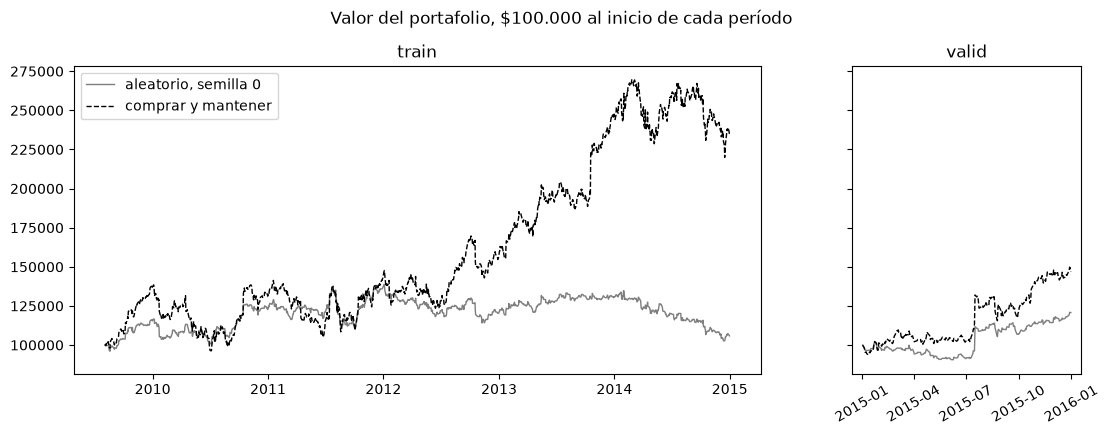

Aleatorio, semilla 0, train: 909 operaciones, $73,974 en costos


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), width_ratios=[3, 1], sharey=True)
for ax, p in zip(axes, PERIODS):
    ax.plot(random_days[p]["value"], color="tab:gray", lw=1, label="aleatorio, semilla 0")
    ax.plot(fixed_days[(p, "comprar y mantener")]["value"], color="black", ls="--", lw=1, label="comprar y mantener")
    ax.set_title(p)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].tick_params(axis="x", labelrotation=30)
axes[0].legend()
fig.suptitle("Valor del portafolio, $100.000 al inicio de cada período", y=1.02)
plt.show()

train_random = random_days["train"]
print(f"Aleatorio, semilla 0, train: {backtest.metrics(train_random)['trades']} operaciones, "
      f"${train_random['cost'].sum():,.0f} en costos")

## El agente DQN frente a las baselines

Los modelos entrenados en la parte 9 (3 semillas de cada recompensa),
evaluados con las mismas funciones.

In [6]:
agents = {"DQN v0": ("investor-v0", "investor-v0"), "DQN v1 (κ = 400 bps)": ("investor-pen400", "investor-penalized-v0")}
agent_rows = []
for name, (save, env_id) in agents.items():
    for seed in SEEDS:
        model = DQN.load(f"saves/dqn_{save}_seed{seed}.zip", device="cpu")
        for p in PERIODS:
            days = backtest.run(lambda obs, m=model: m.predict(obs, deterministic=True)[0], p, env_id)
            agent_rows.append({"período": p, "estrategia": name, "semilla": seed, **backtest.metrics(days)})
agent_runs = pd.DataFrame(agent_rows)

rows = []
for p in PERIODS:
    r = random_runs[random_runs["período"] == p]
    rows.append({"período": p, "estrategia": "aleatorio (mediana de 200)", **r.drop(columns=["período", "semilla"]).median()})
    for name in fixed:
        rows.append({"período": p, "estrategia": name, **fixed_table.loc[(p, name)]})
    for name in agents:
        a = agent_runs[(agent_runs["período"] == p) & (agent_runs["estrategia"] == name)]
        rows.append({"período": p, "estrategia": f"{name} (media de 3)", **a.drop(columns=["período", "estrategia", "semilla"]).mean()})
comparison = pd.DataFrame(rows).set_index(["período", "estrategia"])
fmt(comparison[[c for c in LABELS if c in comparison]])

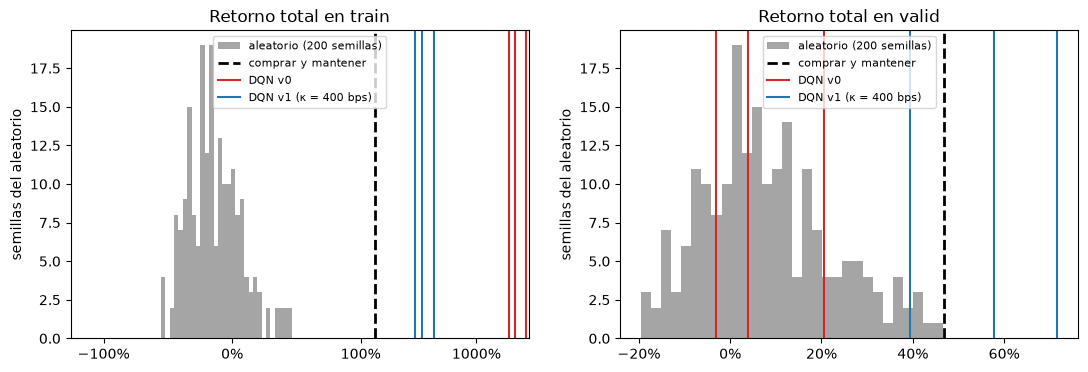

train: el aleatorio supera a comprar y mantener en 0% de las 200 semillas
   DQN v0: supera al 100%–100% de los agentes aleatorios
   DQN v1 (κ = 400 bps): supera al 100%–100% de los agentes aleatorios
valid: el aleatorio supera a comprar y mantener en 0% de las 200 semillas
   DQN v0: supera al 24%–82% de los agentes aleatorios
   DQN v1 (κ = 400 bps): supera al 97%–100% de los agentes aleatorios


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, p in zip(axes, PERIODS):
    r = random_runs.loc[random_runs["período"] == p, "total_return"]
    ax.hist(r, bins=30, color="tab:gray", alpha=0.7, label="aleatorio (200 semillas)")
    ax.axvline(fixed_table.loc[(p, "comprar y mantener"), "total_return"], color="black", ls="--", lw=2,
               label="comprar y mantener")
    for name, color in zip(agents, ["tab:red", "tab:blue"]):
        a = agent_runs[(agent_runs["período"] == p) & (agent_runs["estrategia"] == name)]["total_return"]
        for i, value in enumerate(a):
            ax.axvline(value, color=color, lw=1.5, label=name if i == 0 else None)
    if p == "train":
        ax.set_xscale("symlog", linthresh=1)  # train llega a +2.000 %
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Retorno total en {p}")
    ax.set_ylabel("semillas del aleatorio")
    ax.legend(fontsize=8)
plt.show()

for p in PERIODS:
    r = random_runs.loc[random_runs["período"] == p, "total_return"]
    bh = fixed_table.loc[(p, "comprar y mantener"), "total_return"]
    print(f"{p}: el aleatorio supera a comprar y mantener en {(r > bh).mean():.0%} de las 200 semillas")
    for name in agents:
        a = agent_runs[(agent_runs["período"] == p) & (agent_runs["estrategia"] == name)]["total_return"]
        pct = [(r < v).mean() for v in a]
        print(f"   {name}: supera al {min(pct):.0%}–{max(pct):.0%} de los agentes aleatorios")

## Conclusiones

| | train | validación |
|---|---|---|
| Aleatorio: mediana (percentiles 5–95) | −16 % (−43 % a +23 %) | +6 % (−14 % a +37 %) |
| Comprar y mantener | +134 % | +47 % |
| DQN v0 (media de 3 semillas) | +2.250 % | +7 % |
| DQN v1 (media de 3 semillas) | +355 % | +56 % |

1. **El agente aleatorio pierde por costos.** Cambia de posición 2 de cada 3
   días (~900 operaciones en train) y paga ~$57.000 en costos. Con una
   exposición media de 0,5 debería ganar algo parecido a "siempre 50 %"
   (+59 % en train), pero termina en −16 %: esa diferencia de ~75 puntos es el
   precio de operar sin criterio. Ninguna de las 200 semillas supera a comprar
   y mantener, ni en train ni en validación.
2. **El azar solo ya produce resultados muy dispersos.** En validación, el 90 %
   central de los agentes aleatorios va de −14 % a +37 %. Un resultado de un
   solo año dentro de ese rango no es prueba de habilidad.
3. **DQN v0 no se distingue del azar en validación.** Supera solo al 24–82 %
   de los agentes aleatorios, según la semilla, y su media (+7 %) es casi la
   mediana del azar (+6 %). Su +2.250 % en train es sobreajuste (parte 9).
4. **DQN v1 sí aporta frente al azar.** Supera al 97–100 % de los agentes
   aleatorios, y en media también a comprar y mantener (+56 % contra +47 %),
   con menor drawdown (−9,6 % contra −12,5 %). Como κ se eligió con
   validación, esta comparación es optimista: la evaluación final en test
   dirá si se sostiene.

**Para la evaluación final:** se usarán exactamente estas funciones
(`backtest.buy_and_hold` y `backtest.random_policy` con 200 semillas), el
mismo entorno y el mismo costo de 10 bps, sobre el período de test.